# Single qubit Gates

To make our quantum program more interesting, between initializing the qubits and measuring them, we will perform some operations.  

An important feature of quantum circuits is that the operations (gates) are always reversible!  

These reversible gates can be represented as matrices, and as rotations around the Bloch sphere. 

Let's implement some of the most important operations:

In [59]:
from qiskit import QuantumCircuit, Aer  #assemble,
from math import pi, sqrt
from qiskit.visualization import plot_bloch_multivector, plot_histogram

sim = Aer.get_backend('aer_simulator')

## The X-gate
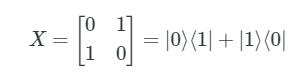

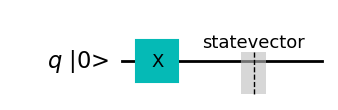

In [60]:
# create a 1-qubit circuit
qc = QuantumCircuit(1)

## initialize qubit
##-----------------> by default QuantumCircuit initializes all qubits to |0> state ;)


# Let's do an X-gate on a |0> qubit and visualize the circuit
qc.x(0)

# save the state vector after operation
qc.save_statevector()

qc.draw(initial_state=True)  #initial_state=True display the initial state

To see the result of the above circuit we use ```plot_bloch_multivector()``` which takes a qubit's statevector.

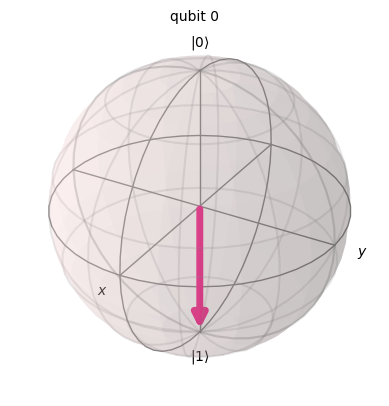

In [61]:
# Let's see the result:

state = sim.run(qc).result().get_statevector()

plot_bloch_multivector(state)

## The Y-gate and Z-gate:

The Y-gate is implemented by the ```.y()``` method.  
The Z-gate is implemented by the ```.z()``` method.  

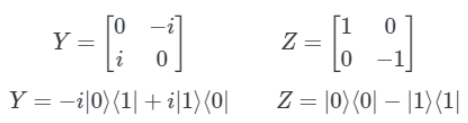

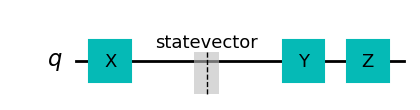

In [62]:
#implementation for illustration:

qc.y(0) # Do Y-gate on qubit 0
qc.z(0) # Do Z-gate on qubit 0
qc.draw()

## Exercice:

Build circuits, intialize and display results to:

1- Show what happens if you apply the Y-gate to the |1> state.  
2- Show what happens if you apply the Z-gate to the |+> state.



In [63]:
## Exercice 1




In [64]:
## Exercice 2





## Hadamard Gate
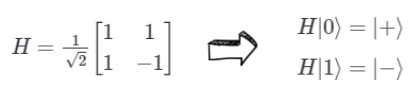

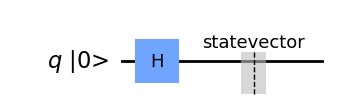

In [65]:
qc = QuantumCircuit(1)
qc.h(0)
qc.save_statevector()
qc.draw(initial_state=True)

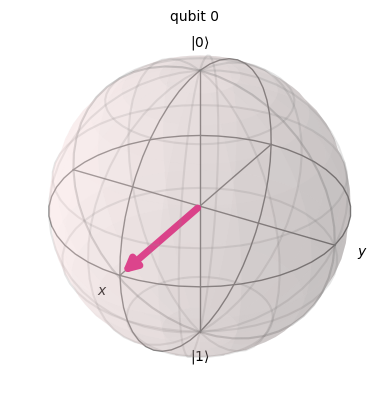

In [66]:
state = sim.run(qc).result().get_statevector()

plot_bloch_multivector(state)

## S gate
The s-gate is implemented by ```.s()```


#### Exercice:
1- Apply the s-gate to the zero state. What happens ?  
2- Create the |+> state with the Hadamard gate, then apply the s-gate. Display the block sphere.  
3- Create the |+> state with the Hadamard gate, then apply the s-gate two time. Display the block sphere.  
4- What is the effect of the s-gate ?  

In [67]:
### your answer here





## S gate
The Sdg-gate is implemented by ```.sdg()```


#### Exercice:
5- What is the effect of the sdg-gate ?  

In [68]:
### your code here





## Solutions:

1- nothing aparently.  
2- goes to the |+i> state.   
3- goes to the |-> state.  
4- S-gate is a rotation with $\phi=\pi/2$ around the z-axis.  
5- Sdg-gate is a rotation with $\phi=-\pi/2$ around the z-axis. It cancels the S-gate.  

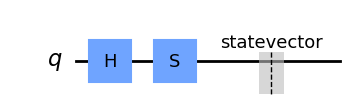

In [69]:
qc = QuantumCircuit(1)
qc.h(0)
qc.s(0)   # Apply S-gate to qubit 0
#qc.sdg(0) # Apply Sdg-gate to qubit 0

qc.save_statevector()
qc.draw()

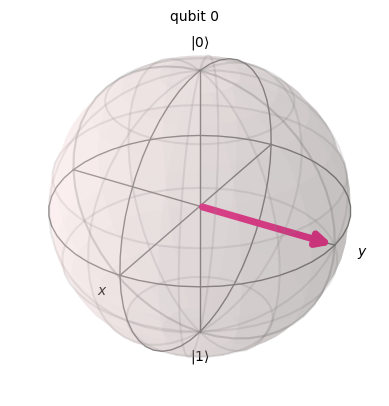

In [70]:
state = sim.run(qc).result().get_statevector()

plot_bloch_multivector(state)

## The T-gate and Tsd-gate
The T-gate is implemented by ```.t()``` method.  
The Tsg-gate is implemented by ```.tdg()``` method.  


## Exercice:

6- What are the effect of the T-gate and Tdg-gate? Try applying the gate to the |+> state or to the |+i> state.  
7- How is the T-gate compared to the S-gate ?.  



In [71]:
### your code here
 



## Solutions:

6- The T-gate is a rotation of $\phi=\pi/4$ around the z-axis. Tsd gate is the reversible of T-gate.  
7- Two T-gates are equivalent to one S-gate: sometimes people say that T^2 = S.


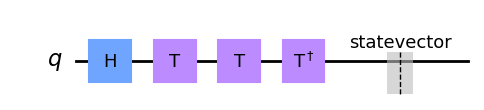

In [72]:
qc = QuantumCircuit(1)
qc.h(0)
qc.t(0)   # Apply T-gate to qubit 0
qc.t(0)   # Apply T-gate to qubit 0
qc.tdg(0) # Apply Tdg-gate to qubit 0

qc.save_statevector()
qc.draw()

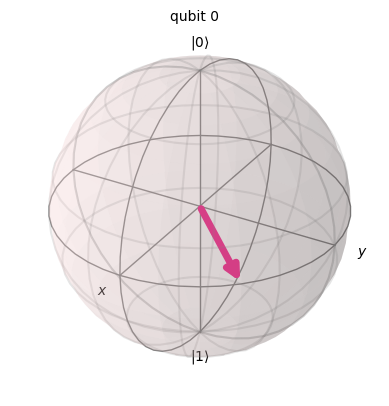

In [73]:
state = sim.run(qc).result().get_statevector()

plot_bloch_multivector(state)

## P gate 
Rotation of $\phi$ around the Z-axis.

In [74]:
# Run the code in this cell to see the widget
from qiskit_textbook.widgets import gate_demo
gate_demo(gates='pauli+h+p')

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01\xe0\x00\x00\x01\xe0\x08\x06\x00\x00\x00}\xd4\xbe…

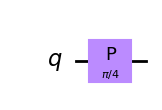

In [75]:
qc = QuantumCircuit(1)
qc.p(pi/4, 0)
qc.draw()

## The U-gate
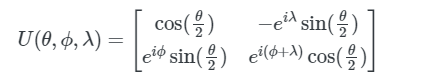

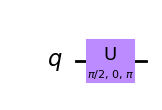

In [76]:
# Let's have U-gate transform a |0> to |+> state
qc = QuantumCircuit(1)
qc.u(pi/2, 0, pi, 0)
qc.draw()

# Initialize -> Apply Operations -> Measure
Let's run a more complx circuit performing operation before measurements.

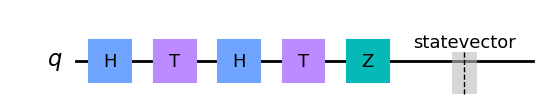

In [77]:

# backend selection
sim = Aer.get_backend('aer_simulator')

# define circuit
circuit = QuantumCircuit(1)

circuit.h(0)
circuit.t(0)
circuit.h(0)
circuit.t(0)
circuit.z(0)

circuit.save_statevector()

circuit.draw()

The operations are applied sequentially, starting on the left and ending on the right in the figure. Let us first initialize a starting quantum state vector and then evolve that state according to the sequence of operations.

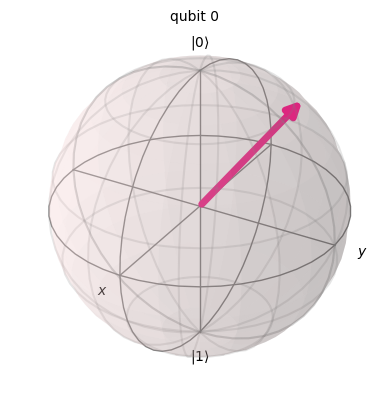

In [78]:
state = sim.run(circuit).result().get_statevector()

plot_bloch_multivector(state)

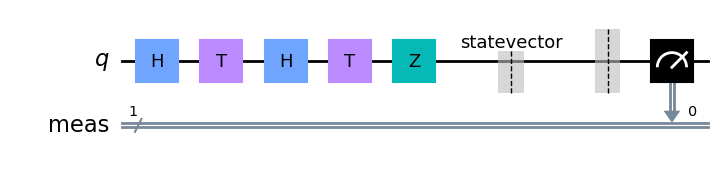

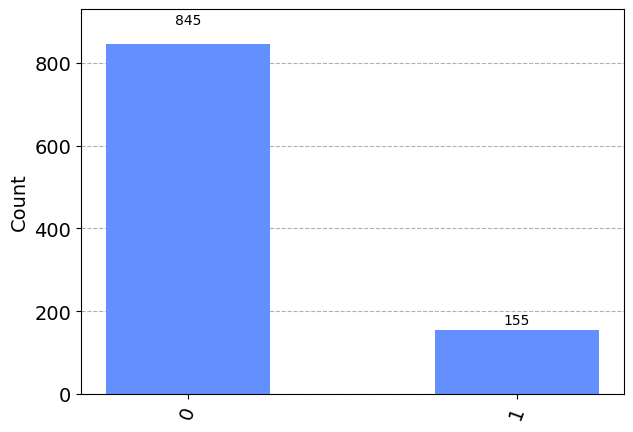

In [79]:
circuit.measure_all()

display(circuit.draw())

result = sim.run(circuit,shots=1000).result()   ## Set to run 1000 times to have statistics

counts = result.get_counts()

plot_histogram(counts)